<a href="https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploratory data analysis of multidimensional poverty in Bolivia

Part of the [GeoDevelopment Observatory of Bolivia](https://quarcs-lab.github.io/geo4bolivia/).

This notebook explores how multidimensional poverty varies across Bolivia's 339 municipalities, and how it relates to population and night-time lights. All data come from the `geo4bolivia` package and refer to 2012, the year of the population census behind the poverty index.

1. **Load the data** with `geo4bolivia`
2. **Descriptive statistics**, for the country and by department
3. **Regional differences**: how poverty is distributed across departments
4. **Population and poverty**: are the most populous municipalities less poor?
5. **Night-time lights and poverty**: can lights from space help predict poverty?

## 0. Setup

In Google Colab the next cell installs the package and the mapping library (a few seconds). Locally, `uv sync` has installed them already.

In [1]:
import importlib.util

missing = [p for p in ["geo4bolivia", "mapclassify"] if importlib.util.find_spec(p) is None]
if missing:
    pkgs = " ".join(missing)
    !pip install -q {pkgs}

In [2]:
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio

import geo4bolivia as geo

if "google.colab" not in sys.modules:
    pio.renderers.default = "plotly_mimetype+notebook_connected"   # keeps the saved notebook small

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", message="Numba not installed")   # mapclassify works without it

## 1. Load the data

Three indicators, all for 2012:

| Variable | Dataset | Meaning |
| --- | --- | --- |
| `sdg1_2_mpi` | `sdg` | Multidimensional Poverty Index (0–1; **higher = poorer**) |
| `pop` | `pop` | Estimated population (WorldPop) |
| `ln_t400NTLpc` | `ntl` | Long-run trend (HP filter) of the log of night-time lights per capita |

`geometry=True` returns a GeoDataFrame with the municipal boundaries and names; `geo.combine` puts the night-time lights and population panels on the same units.

In [3]:
YEAR = 2012

mpi = geo.load("sdg", variables="sdg1_2_mpi", years=YEAR, geometry=True)
covariates = geo.combine(["ntl", "pop"], scale="municipality", years=YEAR)[["geo_id", "ln_t400NTLpc", "pop"]]

# department and province of each municipality, from the units table
units = geo.units()
names = units.set_index("geo_id")["name"]
parents = units.loc[units["scale"] == "municipality", ["geo_id", "department_id", "province_id"]]

gdf = mpi.merge(covariates, on="geo_id").merge(parents, on="geo_id")
gdf["department"] = gdf["department_id"].map(names)
gdf["province"] = gdf["province_id"].map(names)
gdf["rank_mpi"] = gdf["sdg1_2_mpi"].rank(ascending=False, method="min").astype(int)   # 1 = poorest

gdf = gdf[["geo_id", "name", "province", "department", "sdg1_2_mpi", "rank_mpi", "pop", "ln_t400NTLpc", "geometry"]]
print(gdf.shape)
gdf.head()

(339, 9)


,geo_id,name,province,department,sdg1_2_mpi,rank_mpi,pop,ln_t400NTLpc,geometry
0,BO-01-01-01,Azurduy,Azurduy,Chuquisaca,0.440,4,10927.5350,11.048312,"MULTIPOLYGON (((-64.3103 -19.8603, -64.3167 -1..."
1,BO-01-01-02,Tarvita,Azurduy,Chuquisaca,0.380,15,14207.9030,12.329279,"MULTIPOLYGON (((-64.4139 -19.8224, -64.4165 -1..."
2,BO-01-02-01,Villa Serrano,Belisario Boeto,Chuquisaca,0.199,130,11159.8340,12.815315,"MULTIPOLYGON (((-64.4791 -18.8823, -64.4819 -1..."
3,BO-01-03-01,Huacareta,Hernando Siles,Chuquisaca,0.261,62,8394.6611,12.018971,"MULTIPOLYGON (((-64.1604 -20.8874, -64.167 -20..."
4,BO-01-03-02,Monteagudo,Hernando Siles,Chuquisaca,0.166,178,24266.3730,14.603350,"MULTIPOLYGON (((-64.2914 -20.4571, -64.2887 -2..."


Labels for the plots, and a fixed colour for each department:

In [4]:
labels = {
    "sdg1_2_mpi": "Multidimensional poverty index (2012)",
    "pop": "Population (2012)",
    "ln_t400NTLpc": "Log night-time lights per capita (trend, 2012)",
    "rank_mpi": "Poverty rank (1 = poorest)",
    "department": "Department",
    "name": "Municipality",
}
departments = sorted(gdf["department"].unique())
palette = dict(zip(departments, sns.color_palette("tab10", len(departments))))

## 2. Descriptive statistics

- What do we know about the centre and dispersion of poverty?

In [5]:
gdf[["sdg1_2_mpi", "pop", "ln_t400NTLpc", "rank_mpi"]].describe().round(2)

,sdg1_2_mpi,pop,ln_t400NTLpc,rank_mpi
count,339.00,339.00,339.00,339.00
mean,0.18,29725.21,13.03,169.51
std,0.10,106567.22,1.67,97.96
min,0.01,518.92,0.86,1.00
25%,0.10,5951.32,12.05,85.00
50%,0.17,10979.98,13.12,168.00
75%,0.24,20057.19,14.27,254.00
max,0.52,1429553.00,17.07,339.00


In [6]:
by_dep = gdf.groupby("department")["sdg1_2_mpi"].describe().round(3)
by_dep.sort_values("mean", ascending=False)

,count,mean,std,min,25%,50%,75%,max
department,,,,,,,,
Pando,15.0,0.322,0.123,0.057,0.268,0.362,0.370,0.520
Chuquisaca,29.0,0.260,0.095,0.046,0.199,0.249,0.302,0.454
Potosí,40.0,0.204,0.101,0.029,0.136,0.194,0.264,0.403
Beni,19.0,0.196,0.073,0.058,0.158,0.183,0.231,0.371
Cochabamba,47.0,0.175,0.106,0.007,0.080,0.186,0.246,0.386
Oruro,35.0,0.172,0.085,0.010,0.118,0.165,0.244,0.405
La Paz,87.0,0.166,0.072,0.008,0.118,0.164,0.213,0.381
Santa Cruz,56.0,0.122,0.063,0.012,0.070,0.112,0.173,0.280
Tarija,11.0,0.082,0.042,0.026,0.047,0.097,0.106,0.149


The poorest and least poor municipalities:

In [7]:
cols = ["name", "department", "sdg1_2_mpi", "rank_mpi", "pop"]
gdf.nlargest(5, "sdg1_2_mpi")[cols].round({"pop": 0})

,name,department,sdg1_2_mpi,rank_mpi,pop
224,El Sena,Pando,0.520,1,8187.0
227,San Pedro,Pando,0.508,2,3384.0
12,Poroma,Chuquisaca,0.454,3,24101.0
0,Azurduy,Chuquisaca,0.440,4,10928.0
187,El Choro,Oruro,0.405,5,7638.0


In [8]:
gdf.nsmallest(5, "sdg1_2_mpi")[cols].round({"pop": 0})

,name,department,sdg1_2_mpi,rank_mpi,pop
68,Colcapirhua,Cochabamba,0.007,339,54300.0
159,La Paz,La Paz,0.008,338,782053.0
195,Huachacalla,Oruro,0.010,337,849.0
276,Santa Cruz de la Sierra,Santa Cruz,0.012,336,1429553.0
63,Punata,Cochabamba,0.023,335,27142.0


The average municipality has an MPI of 0.18 (median 0.17, standard deviation 0.10), and values range from 0.007 to 0.52. Population is very skewed: the median municipality has about 11,000 inhabitants, while Santa Cruz de la Sierra has 1.43 million.

By department, Pando (mean 0.32) and Chuquisaca (0.26) are the poorest, and Santa Cruz (0.12) and Tarija (0.08) the least poor. The poorest municipalities are El Sena and San Pedro in Pando and Poroma and Azurduy in Chuquisaca. The least poor include the cities of La Paz and Santa Cruz de la Sierra, but also Colcapirhua and Punata (Cochabamba) and the very small Huachacalla (Oruro, about 850 people).

## 3. Regional differences in poverty

- How is poverty distributed across the 339 municipalities and 9 departments?

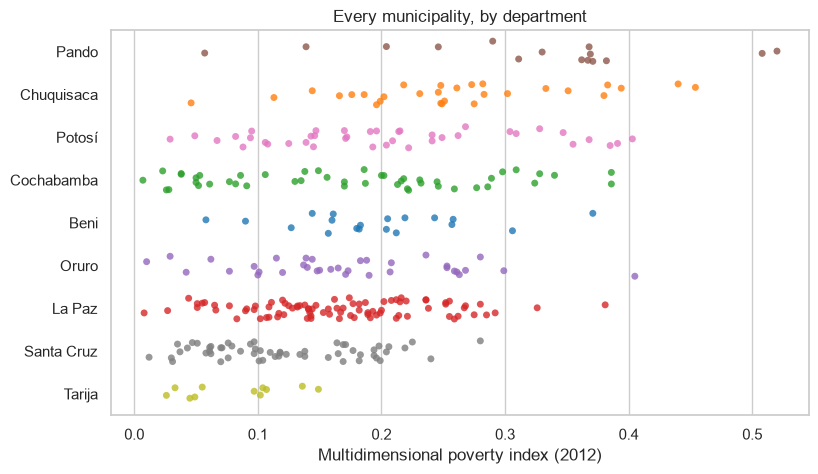

In [9]:
order = by_dep.sort_values("50%", ascending=False).index

fig, ax = plt.subplots(figsize=(9, 5))
sns.stripplot(data=gdf, x="sdg1_2_mpi", y="department", hue="department", order=order,
              palette=palette, size=5, jitter=0.25, alpha=0.8, legend=False, ax=ax)
ax.set(xlabel=labels["sdg1_2_mpi"], ylabel="", title="Every municipality, by department")
plt.show()

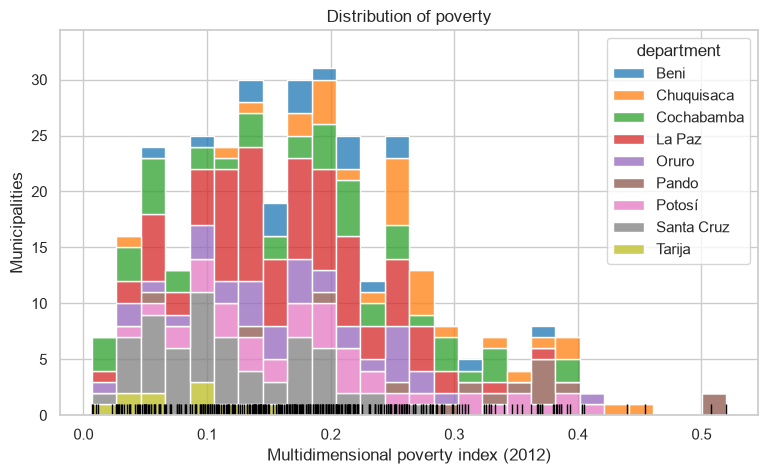

In [10]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(data=gdf, x="sdg1_2_mpi", hue="department", hue_order=departments, palette=palette,
             multiple="stack", bins=26, ax=ax)
sns.rugplot(data=gdf, x="sdg1_2_mpi", color="black", height=0.03, ax=ax)
ax.set(xlabel=labels["sdg1_2_mpi"], ylabel="Municipalities", title="Distribution of poverty")
plt.show()

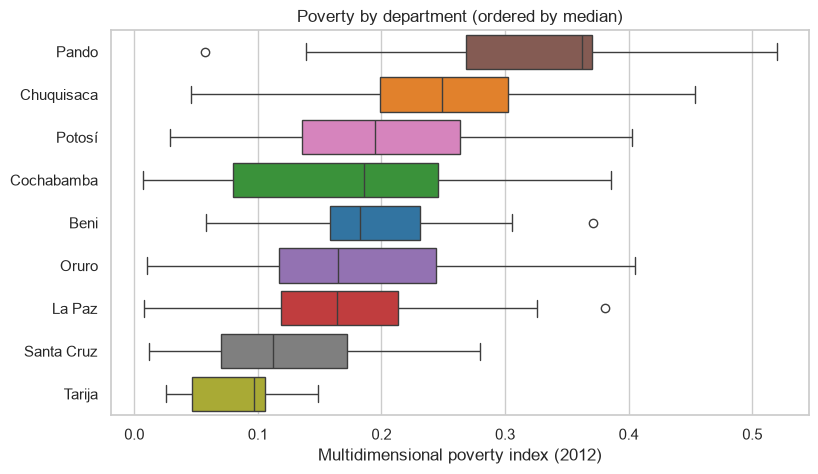

In [11]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=gdf, x="sdg1_2_mpi", y="department", hue="department", order=order,
            palette=palette, legend=False, ax=ax)
ax.set(xlabel=labels["sdg1_2_mpi"], ylabel="", title="Poverty by department (ordered by median)")
plt.show()

Departments differ, but municipalities differ much more within departments than the departments differ from one another. Cochabamba runs from the least poor municipality in the country (0.007) to 0.39, and Potosí from 0.03 to 0.40. Pando is the poorest department: three quarters of its 15 municipalities score 0.27 or more, and only its capital Cobija (0.057) and Porvenir (0.139) are below the national median of 0.17. Every municipality in Tarija scores below 0.15. The distribution is skewed to the right, with a tail of very poor municipalities: 19 of the 24 above 0.35 are in Pando, Chuquisaca and Potosí.

## 4. Population and poverty

- Do the most populous municipalities tend to be less poor?

The 30 most populous municipalities, coloured by poverty:

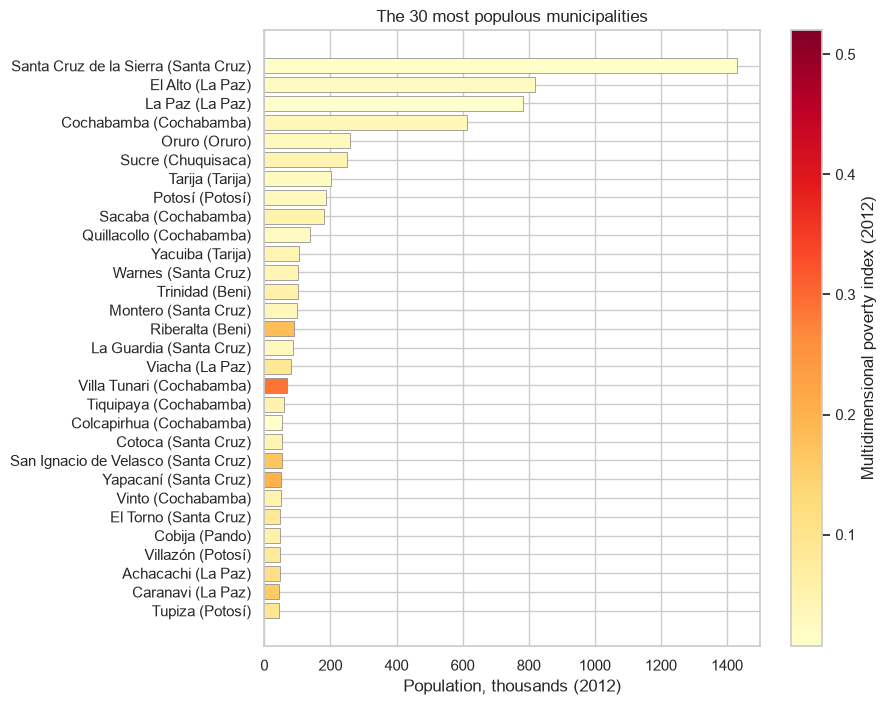

In [12]:
top = gdf.nlargest(30, "pop").sort_values("pop")
norm = plt.Normalize(gdf["sdg1_2_mpi"].min(), gdf["sdg1_2_mpi"].max())
cmap = plt.cm.YlOrRd

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(top["name"] + " (" + top["department"] + ")", top["pop"] / 1e3, color=cmap(norm(top["sdg1_2_mpi"])),
        edgecolor="grey", linewidth=0.5)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=labels["sdg1_2_mpi"])
ax.set(xlabel="Population, thousands (2012)", title="The 30 most populous municipalities")
plt.show()

The treemap nests municipalities within departments: the area of each tile is its population and its colour its poverty (hover for details; click a department to zoom in).

In [13]:
px.treemap(
    gdf, path=[px.Constant("Bolivia"), "department", "name"], values="pop",
    color="sdg1_2_mpi", color_continuous_scale="YlOrRd",
    color_continuous_midpoint=np.average(gdf["sdg1_2_mpi"], weights=gdf["pop"]),
    hover_data={"rank_mpi": True}, labels=labels,
)

In [14]:
px.sunburst(
    gdf, path=["department", "name"], values="pop",
    color="sdg1_2_mpi", color_continuous_scale="YlOrRd",
    color_continuous_midpoint=np.average(gdf["sdg1_2_mpi"], weights=gdf["pop"]),
    hover_data={"rank_mpi": True}, labels=labels,
)

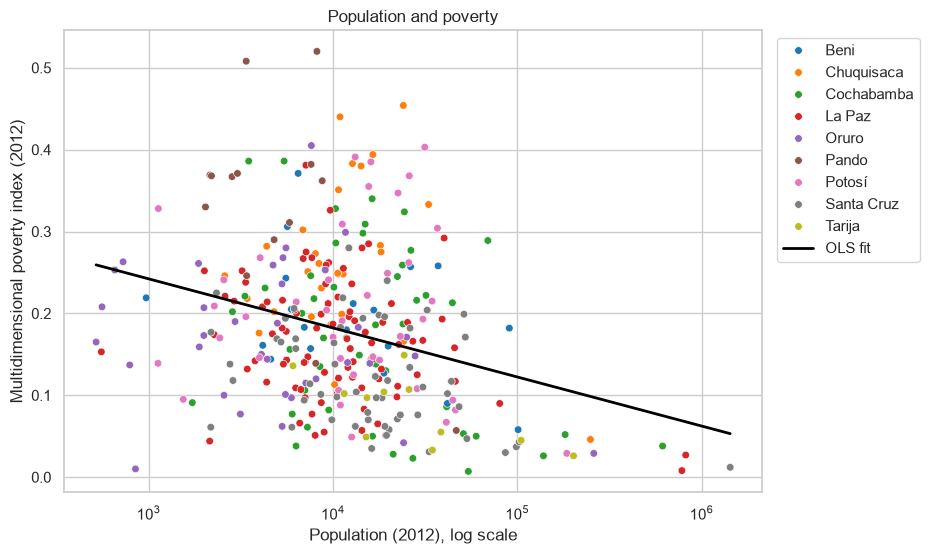

Slope: -0.026 MPI points per log point of population; correlation with log population: -0.30


In [15]:
gdf["ln_pop"] = np.log(gdf["pop"])

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=gdf, x="pop", y="sdg1_2_mpi", hue="department", hue_order=departments,
                palette=palette, s=30, ax=ax)
fit = np.polyfit(gdf["ln_pop"], gdf["sdg1_2_mpi"], 1)
xs = np.linspace(gdf["ln_pop"].min(), gdf["ln_pop"].max(), 100)
ax.plot(np.exp(xs), np.polyval(fit, xs), color="black", lw=2, label="OLS fit")
ax.set_xscale("log")
ax.set(xlabel=labels["pop"] + ", log scale", ylabel=labels["sdg1_2_mpi"], title="Population and poverty")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

print(f"Slope: {fit[0]:.3f} MPI points per log point of population; "
      f"correlation with log population: {gdf['ln_pop'].corr(gdf['sdg1_2_mpi']):.2f}")

In [16]:
top10 = gdf.nlargest(10, "pop")
print(f"The 10 largest municipalities hold {top10['pop'].sum() / gdf['pop'].sum():.0%} of the population; "
      f"their highest MPI is {top10['sdg1_2_mpi'].max():.3f}")
print(f"Share of municipalities with fewer than 20,000 people: {(gdf['pop'] < 20_000).mean():.0%}")
print(f"Mean MPI: simple {gdf['sdg1_2_mpi'].mean():.3f}, "
      f"population-weighted {np.average(gdf['sdg1_2_mpi'], weights=gdf['pop']):.3f}")

The 10 largest municipalities hold 48% of the population; their highest MPI is 0.052
Share of municipalities with fewer than 20,000 people: 75%
Mean MPI: simple 0.179, population-weighted 0.093


More populous municipalities tend to be less poor. The correlation with log population is -0.30, and a tenfold increase in population goes with an MPI about 0.06 lower (0.026 × ln 10). The relationship is loose, though: municipalities with 5,000 to 20,000 people range from almost no poverty to the highest levels.

Population and poverty are also concentrated in different places. The ten largest municipalities hold 48% of the population and none has an MPI above 0.06, while three quarters of municipalities have fewer than 20,000 people. As a result the population-weighted mean MPI (0.09) is about half the simple mean (0.18): the typical Bolivian lives in a much less poor municipality than the typical municipality suggests.

## 5. Night-time lights and poverty

- Can night-time lights help us predict poverty?

Side by side, the poverty map (three natural breaks) and the night-time lights map. Lights are mapped in quintiles: a few almost unlit municipalities are extreme outliers, and natural breaks would give them a class of their own.

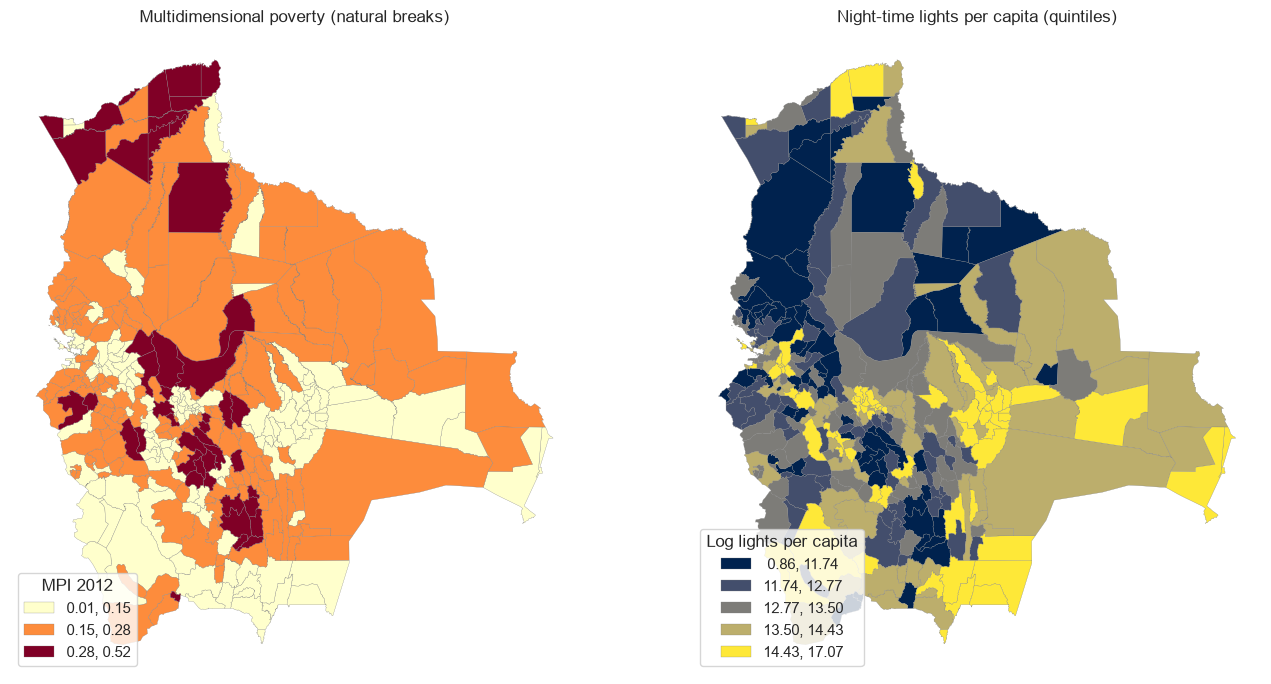

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
gdf.plot(column="sdg1_2_mpi", scheme="FisherJenks", k=3, cmap="YlOrRd", edgecolor="grey", linewidth=0.2,
         legend=True, legend_kwds={"title": "MPI 2012", "loc": "lower left"}, ax=axes[0])
gdf.plot(column="ln_t400NTLpc", scheme="Quantiles", k=5, cmap="cividis", edgecolor="grey", linewidth=0.2,
         legend=True, legend_kwds={"title": "Log lights per capita", "loc": "lower left"}, ax=axes[1])
axes[0].set_title("Multidimensional poverty (natural breaks)")
axes[1].set_title("Night-time lights per capita (quintiles)")
for ax in axes:
    ax.set_axis_off()
plt.tight_layout()
plt.show()

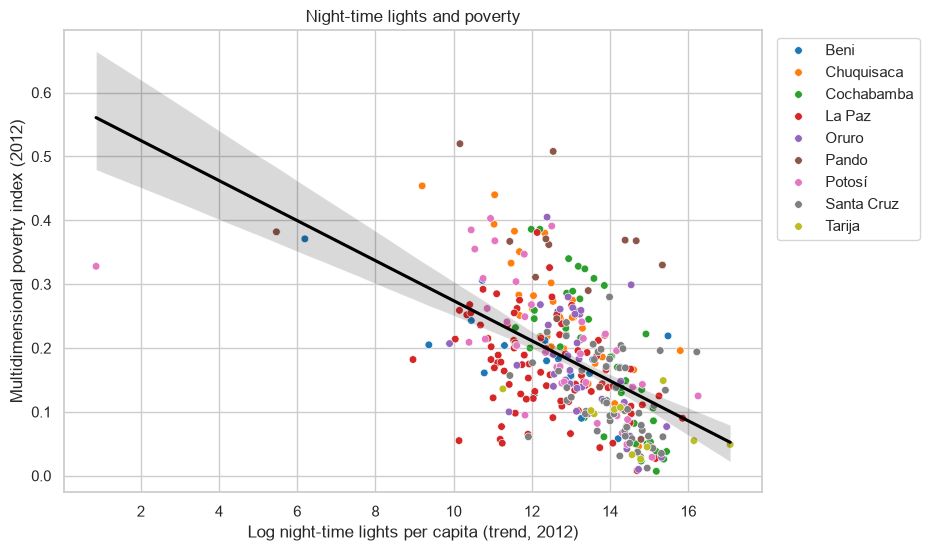

Slope: -0.031; correlation: -0.54; R-squared: 0.29


In [18]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=gdf, x="ln_t400NTLpc", y="sdg1_2_mpi", hue="department", hue_order=departments,
                palette=palette, s=30, ax=ax)
sns.regplot(data=gdf, x="ln_t400NTLpc", y="sdg1_2_mpi", scatter=False, color="black", ax=ax)
ax.set(xlabel=labels["ln_t400NTLpc"], ylabel=labels["sdg1_2_mpi"], title="Night-time lights and poverty")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

fit = np.polyfit(gdf["ln_t400NTLpc"], gdf["sdg1_2_mpi"], 1)
r = gdf["ln_t400NTLpc"].corr(gdf["sdg1_2_mpi"])
print(f"Slope: {fit[0]:.3f}; correlation: {r:.2f}; R-squared: {r**2:.2f}")

A few municipalities are almost unlit. Are they driving the result? The rank (Spearman) correlation and the correlation without them answer that:

In [19]:
dark = gdf["ln_t400NTLpc"] < 7
print(gdf.loc[dark, ["name", "department", "ln_t400NTLpc", "sdg1_2_mpi", "pop"]].round(3).to_string(index=False))
print(f"\nSpearman correlation: {gdf['ln_t400NTLpc'].corr(gdf['sdg1_2_mpi'], method='spearman'):.2f}")
print(f"Pearson correlation without them: {gdf.loc[~dark, 'ln_t400NTLpc'].corr(gdf.loc[~dark, 'sdg1_2_mpi']):.2f}")

       name department  ln_t400NTLpc  sdg1_2_mpi      pop
 Exaltación       Beni         6.194       0.371 6474.773
San Lorenzo      Pando         5.467       0.382 7612.426
   Mojinete     Potosí         0.856       0.328 1129.273

Spearman correlation: -0.58
Pearson correlation without them: -0.54


Brighter municipalities are less poor. The correlation between lights per capita and the MPI is -0.54, so lights alone account for 29% of the variation in poverty across municipalities. An increase of one log point in lights per capita goes with an MPI 0.031 lower.

Three municipalities are almost unlit (Mojinete in Potosí, San Lorenzo in Pando and Exaltación in Beni). They do not drive the result: without them the correlation is still -0.54, and the rank correlation is -0.58.

- How heterogeneous is the relationship between poverty and night-time lights across departments?

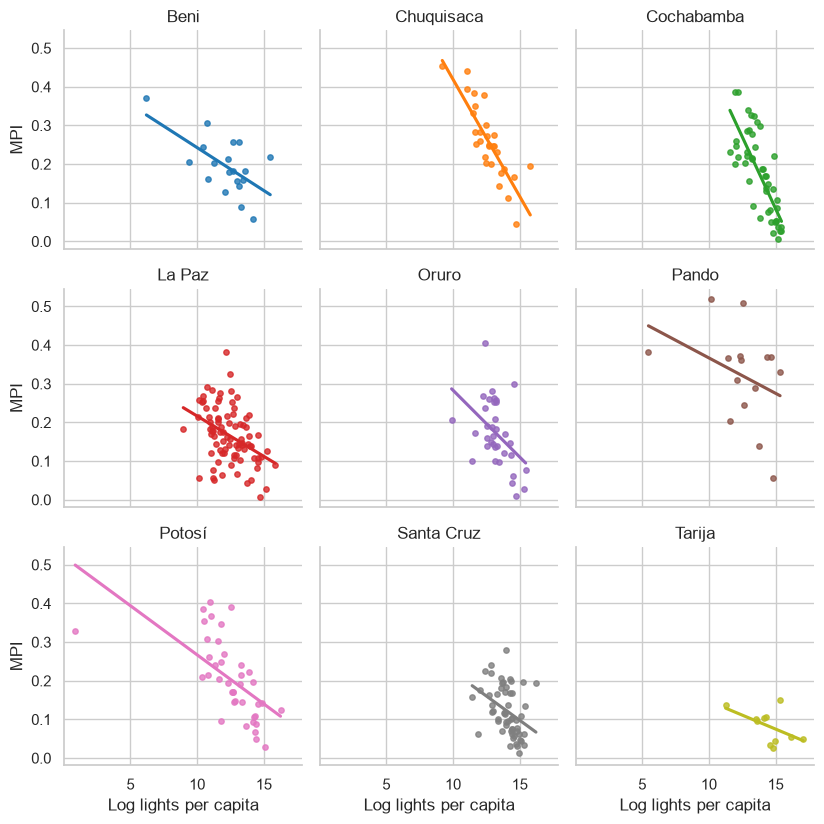

In [20]:
g = sns.lmplot(data=gdf, x="ln_t400NTLpc", y="sdg1_2_mpi", col="department", col_order=departments,
               hue="department", hue_order=departments, palette=palette, col_wrap=3, height=2.8,
               scatter_kws={"s": 15}, ci=None)
g.set_axis_labels("Log lights per capita", "MPI")
g.set_titles("{col_name}")
plt.show()

In [21]:
def fit_by_group(d):
    slope = np.polyfit(d["ln_t400NTLpc"], d["sdg1_2_mpi"], 1)[0]
    return pd.Series({"municipalities": len(d), "slope": slope,
                      "correlation": d["ln_t400NTLpc"].corr(d["sdg1_2_mpi"])})

gdf.groupby("department")[["ln_t400NTLpc", "sdg1_2_mpi"]].apply(fit_by_group).round(3).sort_values("slope")

,municipalities,slope,correlation
department,,,
Cochabamba,47.0,-0.074,-0.771
Chuquisaca,29.0,-0.061,-0.833
Oruro,35.0,-0.035,-0.445
Potosí,40.0,-0.025,-0.603
Santa Cruz,56.0,-0.025,-0.375
Beni,19.0,-0.022,-0.618
La Paz,87.0,-0.021,-0.403
Pando,15.0,-0.018,-0.358
Tarija,11.0,-0.014,-0.517


The relationship is negative in all nine departments, but its strength varies. It is steepest and tightest in Cochabamba (slope -0.074, correlation -0.77) and Chuquisaca (-0.061, -0.83), where lights separate the poorer rural municipalities from the rest well. It is weaker in Pando, Santa Cruz and La Paz (correlations between -0.36 and -0.40) and flattest in Tarija (slope -0.014), where poverty is uniformly low. Potosí's slope is partly pulled by Mojinete, its almost unlit outlier.

## Summary

- Multidimensional poverty in 2012 varies widely across municipalities (0.007 to 0.52), much more within departments than between them. Pando and Chuquisaca are the poorest departments; Tarija and Santa Cruz the least poor.
- Larger municipalities are less poor (correlation -0.30 with log population). The large cities have low poverty and hold half the population, so the population-weighted MPI (0.09) is about half the municipal average (0.18).
- Night-time lights per capita are a stronger predictor (correlation -0.54), robust to the few almost unlit municipalities, and negative in every department.
- The maps show that both poverty and lights are spatially clustered. The companion notebooks [`esda`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda.ipynb) and [`esda_dependence`](https://colab.research.google.com/github/quarcs-lab/geo4bolivia/blob/main/notebooks/esda_dependence.ipynb) measure that clustering with spatial weights, Moran's I and LISA.